In [87]:
import random
import json

import matplotlib.pyplot as plt
import pandas as pd
import datasets
import tokenizers
import transformers

In [88]:
print("tokenizers  :", tokenizers.__version__)
print("transformers:", transformers.__version__)
print("datasets    :", datasets.__version__)

SEED = 42
random.seed(SEED)

tokenizers  : 0.23.3
transformers: 5.22.2
datasets    : 5.1.0


In [89]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download, list_repo_files

PARQUET_REV = "refs/convert/parquet"
pubmed_files = [ 
    hf_hub_download('scientific_papers', f, repo_type='dataset', revision=PARQUET_REV)
    for f in sorted(list_repo_files('scientific_papers',repo_type='dataset', revision=PARQUET_REV)) 
    if f.startswith("pubmed/train/") and f.endswith('.parquet')
]


pubmed = load_dataset("parquet", data_files=pubmed_files, split="train")


wikitext_file = hf_hub_download("wikitext", "wikitext-2-raw-v1/train-00000-of-00001.parquet", repo_type="dataset" )

wikitext = load_dataset("parquet", data_files=wikitext_file, split='train')

In [90]:
N_METRICS = 2000   # abstracts used for corpus-level metric tables
N_TRAIN = 5000     # abstracts used to train our own tokenizer
N_HELDOUT = 1500   # abstracts never seen during training

pubmed_shuffled = pubmed.shuffle(seed=SEED)
medical_metrics_texts = pubmed_shuffled.select(range(N_METRICS))['abstract']
medical_train_texts = pubmed_shuffled.select(range(N_METRICS, N_METRICS+N_TRAIN))['abstract']
medical_heldout_texts = pubmed_shuffled.select(range(N_METRICS+N_TRAIN, N_METRICS+N_TRAIN+N_HELDOUT))['abstract']

general_texts = [t for t in wikitext['text'] if t.strip()][:N_METRICS]

print(f"Medical metrics slice : {len(medical_metrics_texts)} abstracts")
print(f"Medical training slice: {len(medical_train_texts)} abstracts")
print(f"Medical held-out slice: {len(medical_heldout_texts)} abstracts")
print(f"General slice         : {len(general_texts)} non-empty WikiText lines")
print("\nExample held-out abstract:\n", medical_heldout_texts[0][:500])

Medical metrics slice : 2000 abstracts
Medical training slice: 5000 abstracts
Medical held-out slice: 1500 abstracts
General slice         : 2000 non-empty WikiText lines

Example held-out abstract:
  the incidence of anastomotic recurrence after curative resection of colorectal cancer is relatively low compared to that of other types of recurrence , such as hepatic , lung and local recurrence . 
 however , almost all cases of anastomotic recurrence of colorectal cancer occur within 3 years after surgery . 
 we experienced a rare case of anastomotic recurrence in whom colonoscopy revealed no signs of recurrence 3 years after surgery ; however , anastomotic recurrence was detected over 5 year


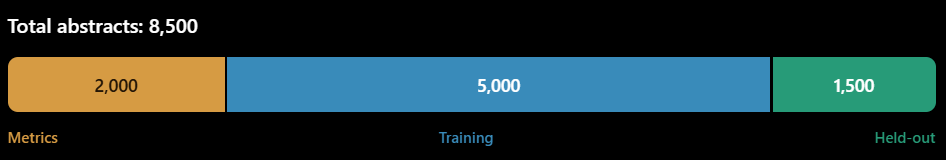

In [91]:
from tokenizers import Tokenizer
from transformers import AutoTokenizer

tok_general = Tokenizer.from_pretrained("openai-community/gpt2") # general-purpose, byte-level BPE
tok_medical = AutoTokenizer.from_pretrained("microsoft/biogpt") # medical, Moses + fairseq-style BPE

def token_list(tok, text):
    """Tokens for `text` from either a raw `tokenizers.Tokenizer` or a transformers tokenizer."""
    if isinstance(tok, Tokenizer):
        return tok.encode(text, add_special_tokens=False).tokens

    return tok.tokenize(text)

print("gpt2   vocab size:", tok_general.get_vocab_size())
print("biogpt vocab size:", tok_medical.vocab_size)

sentence = ("The patient was prescribed amoxicillin-clavulanate for community-acquired pneumonia and referred for echocardiography.")

for name, tok in [("gpt2 (general)", tok_general), ("biogpt (medical)", tok_medical)]:
    toks = token_list(tok, sentence)
    print(f"{name:17s} ({len(toks):2d} tokens): {toks}")

# Ġ - token/word start with space
# </w> - end of the token/word 

gpt2   vocab size: 50257
biogpt vocab size: 42384
gpt2 (general)    (28 tokens): ['The', 'Ġpatient', 'Ġwas', 'Ġprescribed', 'Ġam', 'oxic', 'illin', '-', 'cl', 'av', 'ul', 'an', 'ate', 'Ġfor', 'Ġcommunity', '-', 'acqu', 'ired', 'Ġpneumonia', 'Ġand', 'Ġreferred', 'Ġfor', 'Ġe', 'ch', 'oc', 'ardi', 'ography', '.']
biogpt (medical)  (18 tokens): ['The</w>', 'patient</w>', 'was</w>', 'prescribed</w>', 'amoxicillin</w>', '@-@</w>', 'clavul', 'anate</w>', 'for</w>', 'community</w>', '@-@</w>', 'acquired</w>', 'pneumonia</w>', 'and</w>', 'referred</w>', 'for</w>', 'echocardiography</w>', '.</w>']


In [92]:
def corpus_stats(tok, texts, tok_name, corpus_name):
    n_tokens = sum(len(token_list(tok, t)) for t in texts)
    n_words = sum(len(t.split()) for t in texts)
    n_chars = sum(len(t) for t in texts)
    return {
        "tokenizer": tok_name,
        "corpus": corpus_name,
        "fertility (tokens/word)": n_tokens / n_words,
        "tokens/1k chars": 1000.0 * n_tokens / n_chars,
    }

corpora = [ ("PubMed abstracts (medical)", medical_metrics_texts),
                ("WikiText-2 (general)", general_texts)] ## both of length 2000

tokenizer_list = [("gpt2", tok_general), ("biogpt", tok_medical)]

rows =[ corpus_stats(tok, texts, tname, cname)
        for cname, texts in corpora for tname, tok in tokenizer_list]


df = pd.DataFrame(rows)
df.round(3)

,tokenizer,corpus,fertility (tokens/word),tokens/1k chars
0,gpt2,PubMed abstracts (medical),1.337,218.762
1,biogpt,PubMed abstracts (medical),1.134,185.418
2,gpt2,WikiText-2 (general),1.167,219.171
3,biogpt,WikiText-2 (general),1.298,243.876


In [93]:
# with open('test.txt', 'w') as f:
# #     # f.write(f"{medical_metrics_texts}")
#     a = 0
#     for t in medical_heldout_texts:
#         f.writelines(f"{len(t)} {t}\n")
#         a += len(t)

#     print(a)

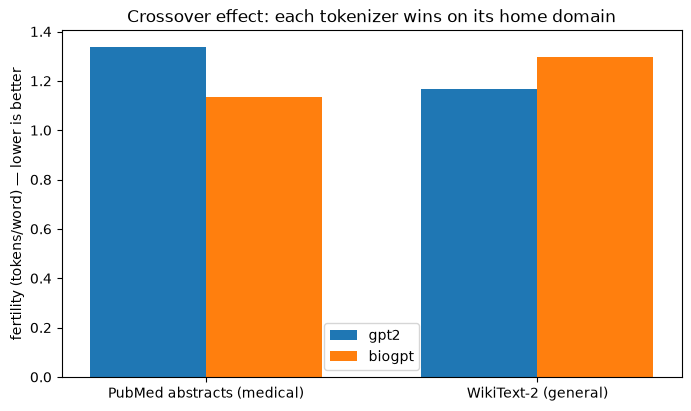

In [94]:
import numpy as np

x = np.arange(len(corpora))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (tname, _) in enumerate(tokenizer_list):
    vals = [df[(df.tokenizer == tname) & (df.corpus == cname)]["fertility (tokens/word)"].iloc[0]
            for cname, _ in corpora]
    ax.bar(x + (i - 0.5) * width, vals, width, label=tname)
ax.set_xticks(x)
ax.set_xticklabels([c[0] for c in corpora])
ax.set_ylabel("fertility (tokens/word) — lower is better")
ax.set_title("Crossover effect: each tokenizer wins on its home domain")
ax.legend()
plt.show()

In [95]:
bert_cased = AutoTokenizer.from_pretrained("bert-base-cased")
bio_clinical = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
pubmedbert = AutoTokenizer.from_pretrained("microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext")

s = "The patient presented with acute myocardial infarction and was started on heparin."
for name, t in [("bert-base-cased", bert_cased),
                ("Bio_ClinicalBERT", bio_clinical),
                ("PubMedBERT", pubmedbert)]:
    print(f"{name:20s} vocab={t.vocab_size:6d}  {t.tokenize(s)}")

print("\nBio_ClinicalBERT vocabulary is exactly bert-base-cased's:",
      bio_clinical.get_vocab() == bert_cased.get_vocab())

bert-base-cased      vocab= 28996  ['The', 'patient', 'presented', 'with', 'acute', 'my', '##oc', '##ard', '##ial', 'in', '##far', '##ction', 'and', 'was', 'started', 'on', 'he', '##par', '##in', '.']
Bio_ClinicalBERT     vocab= 28996  ['the', 'patient', 'presented', 'with', 'acute', 'my', '##oc', '##ard', '##ial', 'in', '##far', '##ction', 'and', 'was', 'started', 'on', 'he', '##par', '##in', '.']
PubMedBERT           vocab= 30522  ['the', 'patient', 'presented', 'with', 'acute', 'myocardial', 'infarction', 'and', 'was', 'started', 'on', 'heparin', '.']

Bio_ClinicalBERT vocabulary is exactly bert-base-cased's: True


In [96]:
from tokenizers import pre_tokenizers
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder


med_tokenizer = Tokenizer(BPE())
med_tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False) # match GPT-2's own setting
med_tokenizer.decoder = ByteLevelDecoder() # must pair with the ByteLevel pre-tokenizer

trainer = BpeTrainer(
    vocab_size=30000,
    min_frequency=2,
    initial_alphabet = pre_tokenizers.ByteLevel.alphabet(),
    special_tokens=["<|endoftext|>"],
    show_progress=True,
)

med_tokenizer.train_from_iterator(medical_train_texts, trainer=trainer)
print("\nTrained vocab size:", med_tokenizer.get_vocab_size())




Trained vocab size: 30000


In [97]:
sentence = ("The patient was prescribed amoxicillin-clavulanate for "
            "community-acquired pneumonia and referred for echocardiography.")

med_tokenizer.save("pubmed_bpe_tokenizer.json")


vocab = med_tokenizer.get_vocab()

with open("pubmed_bpe_vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)


custom_tokenizer = Tokenizer.from_file("pubmed_bpe_tokenizer.json")

encoder = custom_tokenizer.encode(sentence, add_special_tokens=False)

print(f"tokens       : {encoder.tokens}")
print(f"round-trip   : {custom_tokenizer.decode(encoder.ids)}")
print(f"matches orig : {sentence == custom_tokenizer.decode(encoder.ids)}")

tokens       : ['T', 'he', 'Ġpatient', 'Ġwas', 'Ġprescribed', 'Ġamoxicillin', '-', 'cl', 'av', 'ul', 'an', 'ate', 'Ġfor', 'Ġcommunity', '-', 'ac', 'qui', 'red', 'Ġpneumonia', 'Ġand', 'Ġreferred', 'Ġfor', 'Ġechocardiography', '.']
round-trip   : The patient was prescribed amoxicillin-clavulanate for community-acquired pneumonia and referred for echocardiography.
matches orig : True


In [98]:
# What did it learn? Whole-word medical pieces that gpt2 has to build from fragments.
vocab = custom_tokenizer.get_vocab()
for term in ["myocardial", "pneumonia", "methotrexate"]:
    hits = sorted(t for t in vocab if term in t)
    print(f"{term:15s}: {hits[:6]}")

myocardial     : ['Ġendomyocardial', 'Ġmyocardial']
pneumonia      : ['Ġpneumonia', 'Ġpneumoniae']
methotrexate   : ['Ġmethotrexate']


In [99]:
heldout_rows = [
    corpus_stats(tok, medical_heldout_texts, name, "held-out PubMed")
    for name, tok in [("gpt2 (general)", tok_general),
                      ("biogpt (medical)", tok_medical),
                      ("custom tokenizer BPE", custom_tokenizer)]
]
heldout_df = pd.DataFrame(heldout_rows)
heldout_df.round(3)

,tokenizer,corpus,fertility (tokens/word),tokens/1k chars
0,gpt2 (general),held-out PubMed,1.345,219.793
1,biogpt (medical),held-out PubMed,1.137,185.757
2,custom tokenizer BPE,held-out PubMed,1.183,193.311


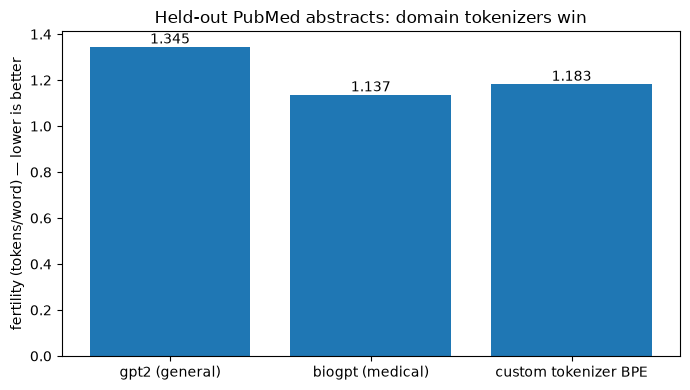

In [100]:
fig, ax = plt.subplots(figsize=(7, 4))
names = heldout_df["tokenizer"]
vals = heldout_df["fertility (tokens/word)"]
bars = ax.bar(names, vals)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_ylabel("fertility (tokens/word) — lower is better")
ax.set_title("Held-out PubMed abstracts: domain tokenizers win")
plt.tight_layout()
plt.show()